In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split

data = load_breast_cancer()
X, y = data.data, data.target
print("Samples, features:", X.shape)
print("target_names:", list(data.target_names), "(0 = malignant, 1 = benign)")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print("Train:", X_train.shape, "| Test:", X_test.shape)

Samples, features: (569, 30)
target_names: [np.str_('malignant'), np.str_('benign')] (0 = malignant, 1 = benign)
Train: (426, 30) | Test: (143, 30)


All data  malignant=212 (37.3%)  benign=357 (62.7%)
Train     malignant=159 (37.3%)  benign=267 (62.7%)
Test      malignant=53 (37.1%)  benign=90 (62.9%)


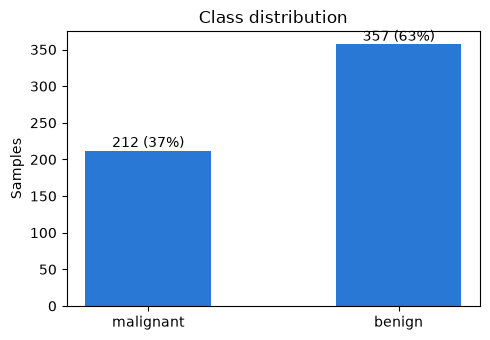

In [2]:
for name, labels in [("All data", y), ("Train", y_train), ("Test", y_test)]:
    counts = np.bincount(labels)
    print(f"{name:9s} malignant={counts[0]} ({counts[0]/len(labels):.1%})  "
          f"benign={counts[1]} ({counts[1]/len(labels):.1%})")

fig, ax = plt.subplots(figsize=(5, 3.5))
counts = np.bincount(y)
ax.bar(["malignant", "benign"], counts, width=0.5, color="#2a78d6")
for i, c in enumerate(counts):
    ax.text(i, c + 5, f"{c} ({c/len(y):.0%})", ha="center")
ax.set_title("Class distribution")
ax.set_ylabel("Samples")
plt.tight_layout(); plt.show()

In [3]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report)

tree = DecisionTreeClassifier(random_state=42)
tree.fit(X_train, y_train)

print("Tree depth:", tree.get_depth(), "| leaves:", tree.get_n_leaves())
print("Train accuracy:", round(tree.score(X_train, y_train), 4))

Tree depth: 7 | leaves: 18
Train accuracy: 1.0


In [4]:
y_pred_tree = tree.predict(X_test)

print("Accuracy :", round(accuracy_score(y_test, y_pred_tree), 4))
print("Precision:", round(precision_score(y_test, y_pred_tree), 4))
print("Recall   :", round(recall_score(y_test, y_pred_tree), 4))
print("F1-score :", round(f1_score(y_test, y_pred_tree), 4))
print()
print(classification_report(y_test, y_pred_tree,
                            target_names=data.target_names, digits=4))

Accuracy : 0.9231
Precision: 0.954
Recall   : 0.9222
F1-score : 0.9379

              precision    recall  f1-score   support

   malignant     0.8750    0.9245    0.8991        53
      benign     0.9540    0.9222    0.9379        90

    accuracy                         0.9231       143
   macro avg     0.9145    0.9234    0.9185       143
weighted avg     0.9247    0.9231    0.9235       143

